# xGoal Model Training

## Import Libraries

In [1]:
import os

# Print current working directory
print(os.getcwd())

# Change to your desired directory
os.chdir('/Users/svasquez/driblab/dl-vision')
print(os.getcwd())

/Users/svasquez/driblab/dl-vision/stats/xG
/Users/svasquez/driblab/dl-vision


In [2]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score, brier_score_loss, confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns


##  Load and Prepare the Data

In [3]:
df_path = "stats/xG/dfs/xG_training_set.csv"
df_path = "stats/xG/dfs/xG_training_set_v2.csv" 

df = pd.read_csv(df_path)
print(f"LENGTH DF {len(df)}")

unique_match_ids = df['match_id'].unique()
print(f"UNIQUE MATCH IDS {len(unique_match_ids)}")


LENGTH DF 5037
UNIQUE MATCH IDS 220


In [4]:
extended_df_path = "stats/xG/dfs/xG_external_matches.csv" 

extended_df = pd.read_csv(extended_df_path)

unique_extended_matches = extended_df['match_id'].unique()


print(f"Length Extended DF {len(extended_df)}")
print(f"Unique extedned matches {len(unique_extended_matches)}")

ext_meta_data = pd.read_csv("/Users/svasquez/AWS_PC/xG_external_matches.csv")


unique_seasons = ext_meta_data['name'].unique()
print(f"UNIQUE SEASONS: {unique_seasons}")

Length Extended DF 7191
Unique extedned matches 294
UNIQUE SEASONS: ['NED I 2024' 'NOR I 2024' 'POL I 2024' 'SUI I 2024' 'BEL I 2024'
 'DEN I 2024']


In [5]:
# Join the two dataframes
df = pd.concat([df, extended_df])
print(f"LENGTH DF {len(df)}")

LENGTH DF 12228


In [6]:
unique_match_ids = df['match_id'].unique()

print(f"UNIQUE MATCH IDS {len(unique_match_ids)}")

UNIQUE MATCH IDS 514


## Load the match ids for Training Only


In [7]:
df['goal_flag'].value_counts()

0    10898
1     1330
Name: goal_flag, dtype: int64

In [8]:
# Get unique match_ids
unique_match_ids = df['match_id'].unique()
print(f"UNIQUE MATCH IDS {len(unique_match_ids)}")

print(f"Avg shots per game {len(df)/ len(unique_match_ids)}")

UNIQUE MATCH IDS 514
Avg shots per game 23.78988326848249


## EDA

In [9]:
# Calculate average distance between Driblab and Wyscout coordinates
average_distance_driblab_wyscout = df['distance_driblab_wyscout'].mean()
print(f"Average Distance Driblab Wyscout: {average_distance_driblab_wyscout}")


Average Distance Driblab Wyscout: 18.34494520771999


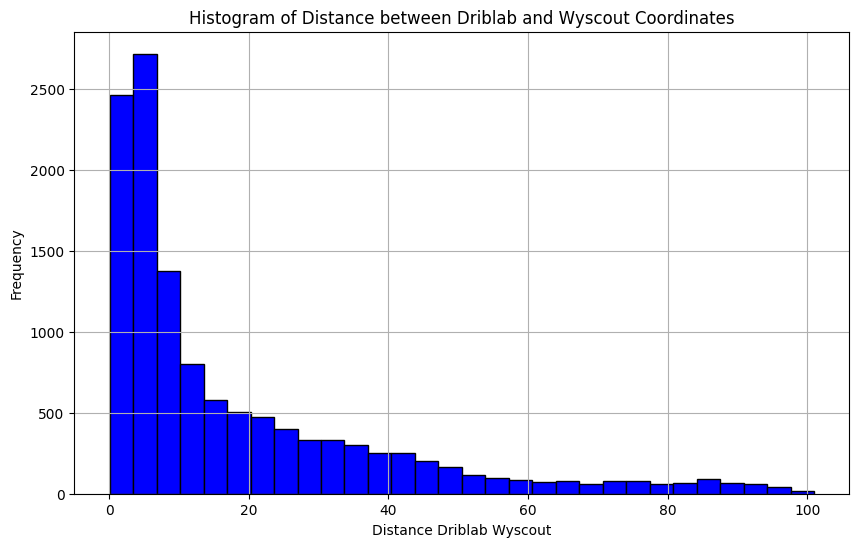

In [10]:


# Create a histogram of distance_driblab_wyscout
plt.figure(figsize=(10, 6))
plt.hist(df['distance_driblab_wyscout'], bins=30, color='blue', edgecolor='black')
plt.title('Histogram of Distance between Driblab and Wyscout Coordinates')
plt.xlabel('Distance Driblab Wyscout')
plt.ylabel('Frequency')
plt.grid(True)
plt.show()


In [11]:
filtered_df = df[df['distance_driblab_wyscout'] < 10]

print(len(df))
print(len(filtered_df))

12228
6514


### Plot a Random Shot

In [12]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

def plot_shot_event(row):
    fig, ax = plt.subplots(figsize=(9, 6))

    # Draw green pitch background
    ax.set_facecolor("#228B22")  # pitch green

    # Pitch outline
    pitch_outline = patches.Rectangle((0, 0), 105, 68, edgecolor='white', facecolor='none', linewidth=2)
    ax.add_patch(pitch_outline)

    # Goal rectangle at center of left side
    goal_width = 7.32
    goal_center_y = 34
    ax.add_patch(patches.Rectangle((0, goal_center_y - goal_width/2), 0.5, goal_width, color="white"))

    # Shooter
    sx, sy = row['shooter_coord.x'], row['shooter_coord.y']
    ax.scatter(sx, sy, color="red", s=100, label="Shooter", zorder=3)

    # Wyscout
    wx, wy = row['wy_shooter_x'], row['wy_shooter_y']
    ax.scatter(wx, wy, color="blue", s=100, label="Wyscout", zorder=3)

    # Line from shooter to goal
    gx, gy = row['goal_coord.x'], row['goal_coord.y']
    ax.plot([sx, gx], [sy, gy], linestyle="--", color="white", linewidth=1.5)

    # Annotate key info
    info_text = [
        f"WY xG: {row['wyscout_xg']:.2f}",
        f"Goal: {'Yes' if row['goal_flag'] else 'No'}",
        f"Body: {row['body_part']}",
        f"Dist: {row['distance']:.2f}m",
        f"Angle: {row['goal_opening_angle']:.1f}°",
        f"Opp2m: {row['opp_count_2']}",
        f"Corridor Opp: {row['opp_in_corridor_count']}"
    ]

    for i, txt in enumerate(info_text):
        ax.text(70, 5 + i*4, txt, color='white', fontsize=10)

    # Axis settings
    ax.set_xlim(0, 105)
    ax.set_ylim(0, 68)
    ax.invert_yaxis()
    ax.axis('on')
    ax.set_xticks([])
    ax.set_yticks([])

    # Title
    ax.set_title(f"Shot by {row['shooter_id']} | Match {row['match_id']}", fontsize=14, color="white")
    ax.legend(loc="lower right", facecolor="white")

    plt.tight_layout()
    plt.show()


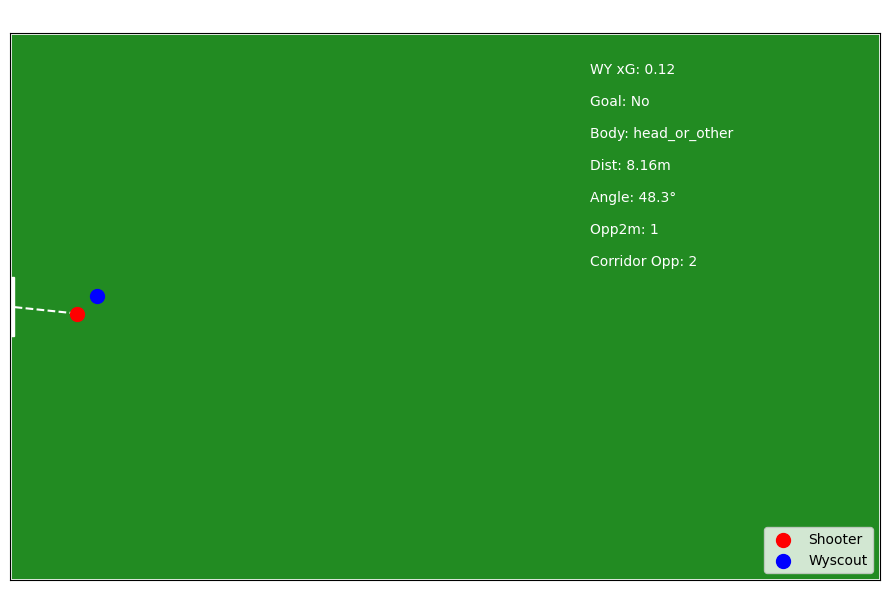

In [13]:
import random

total_shots = len(filtered_df)
random_shot = random.randint(0, total_shots - 1)

plot_shot_event(filtered_df.iloc[random_shot])

In [14]:
df = filtered_df

In [15]:
# Calculate the average distance for goal_flag == True
avg_distance_goal_true = df[df['goal_flag'] == 1]['dist_shooter_goal'].mean()
print(f"Average distance for goal_flag == True: {avg_distance_goal_true}")

# Calculate the average distance for goal_flag == False
avg_distance_goal_false = df[df['goal_flag'] == 0]['dist_shooter_goal'].mean()
print(f"Average distance for goal_flag == False: {avg_distance_goal_false}")


Average distance for goal_flag == True: 12.418003194888179
Average distance for goal_flag == False: 18.181219429347827


### Shooter Speed Analysis

Shooter Speed Description:
count    6478.000000
mean        2.336326
std         1.947017
min         0.000000
25%         1.000000
50%         1.870000
75%         3.260000
max        41.480000
Name: shooter_speed, dtype: float64
99th percentile of Shooter Speed: 8.164599999999991


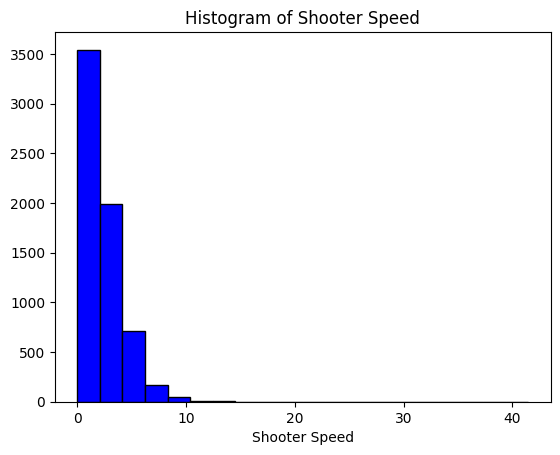

In [57]:
# Describe the 'shooter_speed' column
shooter_speed_description = df['shooter_speed'].describe()
print("Shooter Speed Description:")
print(shooter_speed_description)


plt.hist(df['shooter_speed'], bins=20, color='blue', edgecolor='black')
plt.xlabel('Shooter Speed')
percentile_99 = df['shooter_speed'].quantile(0.99)
print(f"99th percentile of Shooter Speed: {percentile_99}")
plt.title('Histogram of Shooter Speed')
plt.show()

In [58]:
df.columns

Index(['match_id', 'event_id', 'attacking_side', 'row_num', 'shooter_id',
       'body_part', 'shot_time', 'shooter_dir_x', 'shooter_dir_y', 'distance',
       'distance_driblab_wyscout', 'theta1', 'theta2', 'goal_opening_angle',
       'dir_angle', 'shooter_coord.x', 'shooter_coord.y', 'wy_shooter_x',
       'wy_shooter_y', 'goal_coord.x', 'goal_coord.y', 'shooter_speed',
       'tm_count_5', 'tm_count_10', 'opp_count_2', 'opp_count_5',
       'opp_count_10', 'dist_shooter_sideline', 'num_opp2plyr_goal_shooter',
       'dist_shooter_goal', 'dist_opponent_shooter', 'opp_in_corridor_count',
       'dist2offside', 'offside', 'goal_flag', 'wyscout_xg'],
      dtype='object')

Correlation between Distance Shooter Goal and Wyscout xG: -0.541501543967989


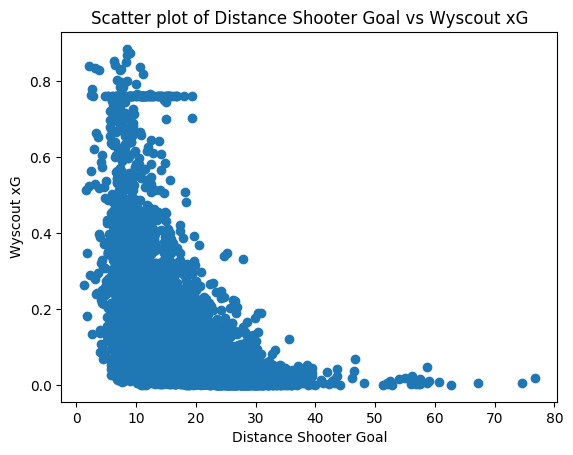

In [16]:


plt.scatter(df['dist_shooter_goal'], df['wyscout_xg'])
plt.xlabel('Distance Shooter Goal')
plt.ylabel('Wyscout xG')
correlation = df['dist_shooter_goal'].corr(df['wyscout_xg'])
print(f"Correlation between Distance Shooter Goal and Wyscout xG: {correlation}")
plt.title('Scatter plot of Distance Shooter Goal vs Wyscout xG')
plt.show()

## Keep only Relevant Features

In [17]:
df.columns

Index(['match_id', 'event_id', 'attacking_side', 'row_num', 'shooter_id',
       'body_part', 'shot_time', 'shooter_dir_x', 'shooter_dir_y', 'distance',
       'distance_driblab_wyscout', 'theta1', 'theta2', 'goal_opening_angle',
       'dir_angle', 'shooter_coord.x', 'shooter_coord.y', 'wy_shooter_x',
       'wy_shooter_y', 'goal_coord.x', 'goal_coord.y', 'shooter_speed',
       'tm_count_5', 'tm_count_10', 'opp_count_2', 'opp_count_5',
       'opp_count_10', 'dist_shooter_sideline', 'num_opp2plyr_goal_shooter',
       'dist_shooter_goal', 'dist_opponent_shooter', 'opp_in_corridor_count',
       'dist2offside', 'offside', 'goal_flag', 'wyscout_xg'],
      dtype='object')

In [18]:

# Drop rows with missing values 
df = df.dropna()

# Target variable
y = df['goal_flag']

# Select features 

drop_cols = ['match_id', 'attacking_side', 'event_id', 'row_num', 'shooter_id','theta1',
            'shot_time', 'goal_coord.y','theta2', 'body_part', 'distance', 'wyscout_xg',
            'goal_flag', 'distance_driblab_wyscout', 'dist_shooter_sideline', 'wy_shooter_x', 'wy_shooter_y',
            'shooter_coord.x', 'shooter_coord.y']

# Get a list of the df columns without the drop_cols list
remaining_cols = [col for col in df.columns if col not in drop_cols]


for col in remaining_cols:
    print(f"Column: {col}")



X = df[remaining_cols]

Column: shooter_dir_x
Column: shooter_dir_y
Column: goal_opening_angle
Column: dir_angle
Column: goal_coord.x
Column: shooter_speed
Column: tm_count_5
Column: tm_count_10
Column: opp_count_2
Column: opp_count_5
Column: opp_count_10
Column: num_opp2plyr_goal_shooter
Column: dist_shooter_goal
Column: dist_opponent_shooter
Column: opp_in_corridor_count
Column: dist2offside
Column: offside


## Train/Test Split

In [19]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

## Build and Fit Base Model

In [20]:
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

pipeline = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
pipeline.fit(X_train, y_train)


Pipeline(steps=[('standardscaler', StandardScaler()),
                ('logisticregression', LogisticRegression(max_iter=1000))])

## Evaluate Base Model

In [21]:
from sklearn.metrics import classification_report, roc_auc_score, brier_score_loss

y_probs = pipeline.predict_proba(X_test)[:, 1]
print(classification_report(y_test, pipeline.predict(X_test)))
print("ROC-AUC:", roc_auc_score(y_test, y_probs))
print("Brier Score Loss:", brier_score_loss(y_test, y_probs))


              precision    recall  f1-score   support

           0       0.91      1.00      0.95      1174
           1       0.33      0.02      0.03       122

    accuracy                           0.90      1296
   macro avg       0.62      0.51      0.49      1296
weighted avg       0.85      0.90      0.86      1296

ROC-AUC: 0.7799801714748511
Brier Score Loss: 0.07512750981627375


## Calibrate Model

In [22]:
from sklearn.calibration import CalibratedClassifierCV

calibrated_model = CalibratedClassifierCV(base_estimator=pipeline, method='isotonic', cv=5)
calibrated_model.fit(X_train, y_train)


CalibratedClassifierCV(base_estimator=Pipeline(steps=[('standardscaler',
                                                       StandardScaler()),
                                                      ('logisticregression',
                                                       LogisticRegression(max_iter=1000))]),
                       cv=5, method='isotonic')

In [23]:
y_probs_cal = calibrated_model.predict_proba(X_test)[:, 1]
print("Brier Score (Calibrated):", brier_score_loss(y_test, y_probs_cal))


Brier Score (Calibrated): 0.07512347435975425


In [27]:
X_test.iloc[1]

shooter_dir_x                  0.09
shooter_dir_y                 -0.32
goal_opening_angle            24.32
dir_angle                     13.62
goal_coord.x                 105.00
shooter_speed                  3.32
tm_count_5                     1.00
tm_count_10                    2.00
opp_count_2                    0.00
opp_count_5                    1.00
opp_count_10                   3.00
num_opp2plyr_goal_shooter      0.00
dist_shooter_goal             16.99
dist_opponent_shooter          2.41
opp_in_corridor_count          2.00
dist2offside                   5.57
offside                        0.00
Name: 5035, dtype: float64

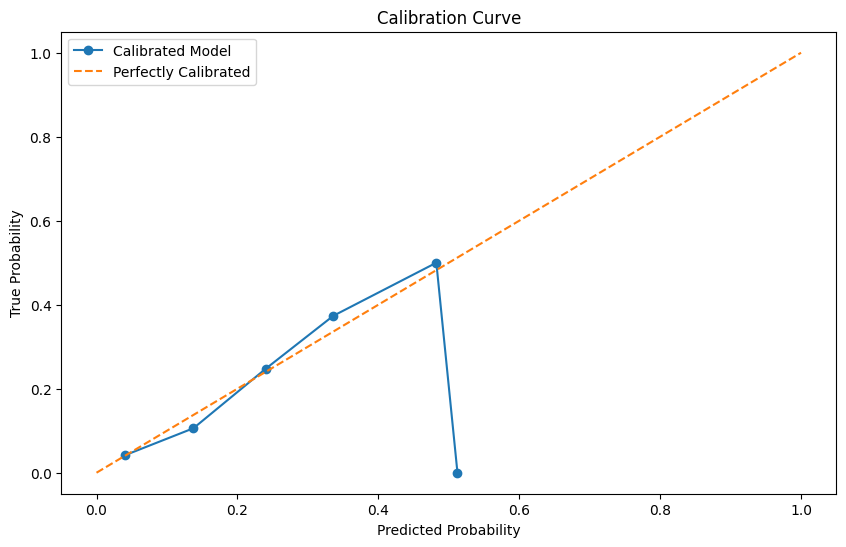

In [24]:
from sklearn.calibration import calibration_curve
import matplotlib.pyplot as plt

prob_true, prob_pred = calibration_curve(y_test, y_probs_cal, n_bins=10)

plt.figure(figsize=(10, 6))
plt.plot(prob_pred, prob_true, marker='o', label='Calibrated Model')
plt.plot([0, 1], [0, 1], linestyle='--', label='Perfectly Calibrated')
plt.xlabel('Predicted Probability')
plt.ylabel('True Probability')
plt.title('Calibration Curve')
plt.legend()
plt.show()


## Examine Model's Coefficients

In [338]:


# Get the trained logistic regression model from the pipeline
model = pipeline.named_steps['logisticregression']
scaler = pipeline.named_steps['standardscaler']

# Get feature names and coefficients
coeffs = model.coef_[0]
feature_names = X_train.columns

# If you scaled data, interpret on scaled basis
importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': coeffs,
    'Abs_Coefficient': abs(coeffs)
}).sort_values(by='Abs_Coefficient', ascending=False)

importance_df


,Feature,Coefficient,Abs_Coefficient
12,dist_shooter_goal,-1.184074,1.184074
5,shooter_speed,0.305479,0.305479
14,opp_in_corridor_count,-0.218206,0.218206
15,dist2offside,-0.212468,0.212468
3,dir_angle,-0.184625,0.184625
13,dist_opponent_shooter,0.142478,0.142478
10,opp_count_10,-0.121986,0.121986
2,goal_opening_angle,-0.111982,0.111982
7,tm_count_10,-0.068615,0.068615
16,offside,-0.068047,0.068047


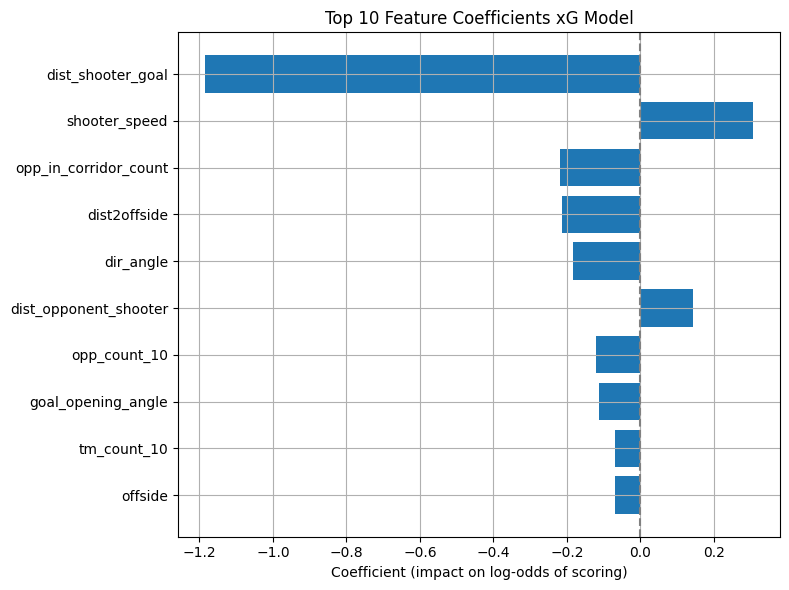

In [339]:


top_n = 10
top_features = importance_df.head(top_n)
plt.figure(figsize=(8, 6))
plt.barh(top_features['Feature'], top_features['Coefficient'])
plt.title(f"Top {top_n} Feature Coefficients xG Model")
plt.axvline(0, color='gray', linestyle='--')
plt.xlabel("Coefficient (impact on log-odds of scoring)")
plt.gca().invert_yaxis()
plt.grid(True)
plt.tight_layout()
plt.show()


### Test with Dynamic Features

In [55]:
features = {'shooter_dir_x': -1.5599999999999987, 
            'shooter_dir_y': 0.28000000000000114,
            'distance': 20.615033349475816,
            'shot_time': 241.96,
            'shooter_coord.x': 20.14,
            'shooter_coord.y': 38.4,
            'goal_coord.x': 0,
            'goal_coord.y': 34,
            'theta1': 22.499325582469908,
            'theta2': 157.50067441753012,
            'goal_opening_angle': 20.13,
            'dir_angle': 12.323814739426645,
            # 'shooter_speed': 15.84929020492805,
            'shooter_speed': 2.84929020492805,
            'tm_count_5': 0,
            'tm_count_10': 0,
            'opp_count_2': 0,
            'opp_count_5': 1,
            'opp_count_10': 1,
            'dist_shooter_sideline': 20.14,
            'num_opp2plyr_goal_shooter': 0,
            'dist_shooter_goal': 20.615033349475816,
            'dist_opponent_shooter': 2.0059162494979703,
            'opp_in_corridor_count': 1,
            'dist2offside': 8.49,
            'offside': False}


features_df = pd.DataFrame([features])



features_df.iloc[0]

shooter_dir_x                     -1.56
shooter_dir_y                      0.28
distance                      20.615033
shot_time                        241.96
shooter_coord.x                   20.14
shooter_coord.y                    38.4
goal_coord.x                          0
goal_coord.y                         34
theta1                        22.499326
theta2                       157.500674
goal_opening_angle                20.13
dir_angle                     12.323815
shooter_speed                   2.84929
tm_count_5                            0
tm_count_10                           0
opp_count_2                           0
opp_count_5                           1
opp_count_10                          1
dist_shooter_sideline             20.14
num_opp2plyr_goal_shooter             0
dist_shooter_goal             20.615033
dist_opponent_shooter          2.005916
opp_in_corridor_count                 1
dist2offside                       8.49
offside                           False


In [56]:


# Predict using the calibrated model
features_for_prediction = features_df[remaining_cols]
xg_prediction = calibrated_model.predict_proba(features_for_prediction)[0, 1]
print(f"Predicted xG: {xg_prediction}")


Predicted xG: 0.0994100239250427


In [45]:
# The 'CalibratedClassifierCV' object does not have an 'intercept_' attribute.
# If you need the intercept, you should access it from the base estimator.
calibrated_model.base_estimator.named_steps['logisticregression'].intercept_

array([-2.71575514])

In [46]:
uncalibrated_proba = calibrated_model.base_estimator.predict_proba(features_for_prediction)[0,1]
print(uncalibrated_proba)


0.49757743096452034


## Benchmark with Wyscout xG

In order to validate the performance of the custom xG model, we benchmark it against the xG values provided by Wyscout. Wyscout xG is widely used in the football analytics industry and offers a reliable reference for comparison.

We evaluate the correlation between the predicted xG from our model and the Wyscout xG values, using metrics such as Mean Absolute Error (MAE), R² score, and Pearson correlation coefficient. This will help assess how closely our model replicates the underlying scoring probabilities as estimated by Wyscout.


In [343]:
# Select the subset of data with no missing values in model features
df_predict = df.dropna(subset=remaining_cols).copy()

# Generate model predictions (probability of scoring)
df_predict['xg_model'] = calibrated_model.predict_proba(df_predict[remaining_cols])[:, 1]

# Merge back to original DataFrame (if df_predict is a filtered version)
df = df.merge(df_predict[['event_id', 'xg_model']], on='event_id', how='left')


In [346]:
df

,match_id,event_id,attacking_side,row_num,shooter_id,body_part,shot_time,shooter_dir_x,shooter_dir_y,distance,...,dist_shooter_sideline,num_opp2plyr_goal_shooter,dist_shooter_goal,dist_opponent_shooter,opp_in_corridor_count,dist2offside,offside,goal_flag,wyscout_xg,xg_model
0,622555,2466773064,left,218,1297322,left_foot,20,-0.35,0.04,22.46,...,22.05,1,22.46,6.80,1,12.11,0,0,0.078750,0.096656
1,622555,2466771965,right,14626,1281301,right_foot,1457,0.42,0.08,17.62,...,9.34,0,17.62,0.99,1,-0.49,1,0,0.239100,0.100552
2,622555,2466772089,right,19327,1732978,right_foot,1926,0.01,-0.28,24.46,...,17.76,1,24.46,2.03,3,8.00,0,0,0.050930,0.028763
3,622555,2466772178,right,22309,1732978,right_foot,2223,0.24,-0.04,11.86,...,3.46,2,11.86,0.41,3,3.66,0,0,0.258600,0.091537
4,622555,2466772036,left,25706,1169625,left_foot,2561,-0.64,-0.42,12.43,...,10.66,0,12.43,2.97,3,3.14,0,1,0.344500,0.347075
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6473,611334,2342132094,right,25702,138425,left_foot,2566,0.39,0.15,19.61,...,5.07,3,19.61,3.74,2,-1.02,1,0,0.054260,0.071877
6474,611334,2342132139,right,29442,1173318,right_foot,3023,-0.33,0.20,18.38,...,1.77,3,18.38,4.31,5,4.19,0,0,0.006907,0.066282
6475,611334,2342132285,right,37461,88469,left_foot,3824,-0.56,0.20,28.87,...,23.54,2,28.87,5.51,4,17.92,0,0,0.039290,0.028763
6476,611334,2342132494,right,45749,1168235,right_foot,4654,-0.11,-0.04,25.58,...,20.08,1,25.58,4.36,4,11.82,0,0,0.052710,0.013374


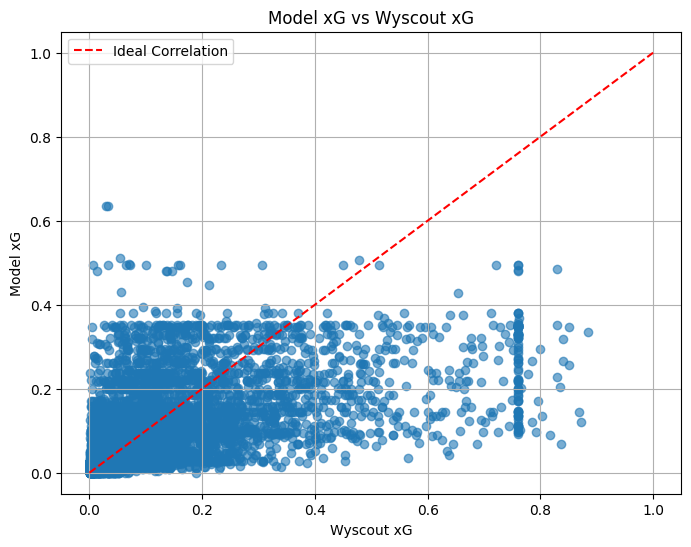

Mean Absolute Error (MAE): 0.0789
R² Score: 0.2614
Pearson Correlation: 0.5481


In [347]:
from sklearn.metrics import mean_absolute_error, r2_score
from scipy.stats import pearsonr
import matplotlib.pyplot as plt

# Scatter plot for visual comparison
plt.figure(figsize=(8, 6))
plt.scatter(df['wyscout_xg'], df['xg_model'], alpha=0.6)
plt.xlabel('Wyscout xG')
plt.ylabel('Model xG')
plt.title('Model xG vs Wyscout xG')
plt.plot([0, 1], [0, 1], 'r--', label='Ideal Correlation')
plt.legend()
plt.grid(True)
plt.show()

# Evaluation metrics
mae = mean_absolute_error(df['wyscout_xg'], df['xg_model'])
r2 = r2_score(df['wyscout_xg'], df['xg_model'])
corr, _ = pearsonr(df['wyscout_xg'], df['xg_model'])

print(f"Mean Absolute Error (MAE): {mae:.4f}")
print(f"R² Score: {r2:.4f}")
print(f"Pearson Correlation: {corr:.4f}")


## Save model

In [348]:
import joblib

joblib.dump(calibrated_model, 'stats/xG/models/xg_logistic_calibrated_model.pkl')


['stats/xG/models/xg_logistic_calibrated_model.pkl']

In [349]:
# Save feature names
joblib.dump(remaining_cols, 'stats/xG/models/xg_logistic_calibrated_feature_names.pkl')

['stats/xG/models/xg_logistic_calibrated_feature_names.pkl']